# 🌲 PHẦN 3: HỌC CÓ GIÁM SÁT (SUPERVISED CLASSIFICATION)
### Mục tiêu: Nhận diện chính xác 5 nhóm hành vi mạng bằng Random Forest
---
### Cơ sở kỹ thuật:
- Sử dụng mô hình **Random Forest Classifier (Ensemble Bagging)** gồm 50 cây quyết định nhị phân.
- Đánh giá phân loại 5 lớp: `Normal`, `DoS`, `Probe`, `R2L`, `U2R`.
- Trực quan hóa **Ma trận nhầm lẫn (Confusion Matrix)** và **Đặc trưng quan trọng nhất (Feature Importance)**.


In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

BASE_DIR = Path("..").resolve()
TRAIN_FILE = BASE_DIR / "data" / "KDDTrain+.txt"
if not TRAIN_FILE.exists():
    TRAIN_FILE = Path(r"D:\data_miner\archive\KDDTrain+.txt")

COLUMN_NAMES = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty'
]
CATEGORICAL_COLS = ['protocol_type', 'service', 'flag']
SKEWED_COLS = ['duration', 'src_bytes', 'dst_bytes']
NUMERIC_COLS = [c for c in COLUMN_NAMES if c not in CATEGORICAL_COLS + ['label', 'difficulty']]

ATTACK_MAP = {
    'normal': 'Normal',
    'neptune': 'DoS', 'smurf': 'DoS', 'pod': 'DoS', 'teardrop': 'DoS', 'land': 'DoS', 'back': 'DoS',
    'apache2': 'DoS', 'udpstorm': 'DoS', 'processtable': 'DoS', 'mailbomb': 'DoS',
    'portsweep': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 'satan': 'Probe', 'saint': 'Probe', 'mscan': 'Probe',
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 'multihop': 'R2L',
    'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L', 'snmpguess': 'R2L', 'httptunnel': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'perl': 'U2R', 'rootkit': 'U2R', 'ps': 'U2R', 'xterm': 'U2R'
}

df = pd.read_csv(TRAIN_FILE, names=COLUMN_NAMES, header=None, nrows=5000)
for c in CATEGORICAL_COLS:
    df[c] = df[c].astype(str).str.strip()
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['attack_cat'] = df['label'].map(lambda x: ATTACK_MAP.get(x, 'Normal'))

df_num = df[NUMERIC_COLS].copy()
for col in SKEWED_COLS:
    df_num[col] = np.log1p(np.maximum(0, df_num[col].astype(np.float32)))
scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X = np.hstack([scaler.fit_transform(df_num.values), encoder.fit_transform(df[CATEGORICAL_COLS])])
y = df['attack_cat'].values


### 1. Huấn luyện Random Forest và Báo cáo hiệu năng


In [2]:
rf = RandomForestClassifier(n_estimators=50, max_depth=12, random_state=42, n_jobs=1)
rf.fit(X, y)

acc = rf.score(X, y) * 100
print(f"✅ Độ chính xác trên tập Train: {acc:.2f}%")
print("Báo cáo phân loại chi tiết:")
print(classification_report(y, rf.predict(X)))


✅ Độ chính xác trên tập Train: 99.96%
Báo cáo phân loại chi tiết:
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      1847
      Normal       1.00      1.00      1.00      2648
       Probe       1.00      1.00      1.00       461
         R2L       1.00      0.98      0.99        43
         U2R       1.00      1.00      1.00         1

    accuracy                           1.00      5000
   macro avg       1.00      0.99      1.00      5000
weighted avg       1.00      1.00      1.00      5000



### 2. Trực quan hóa Ma trận nhầm lẫn & Tầm quan trọng của đặc trưng


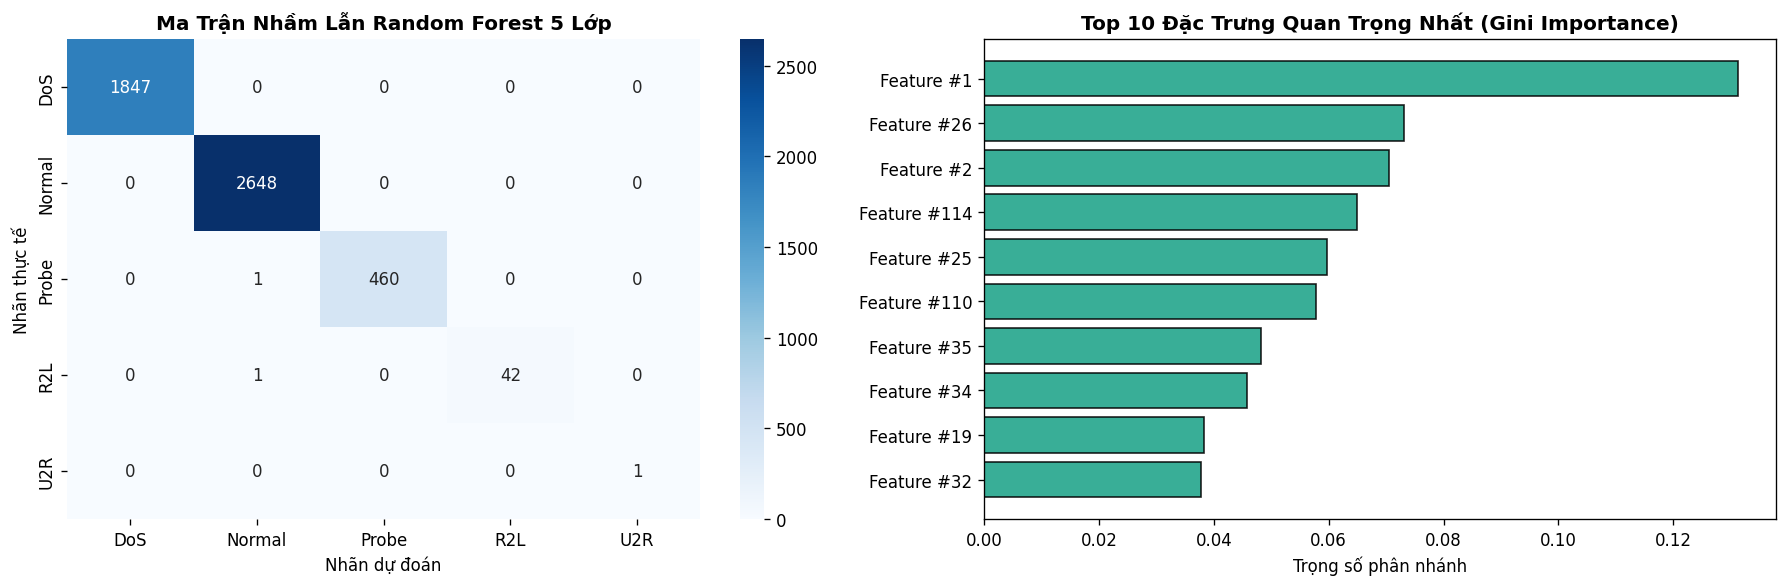

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), dpi=120)

# 1. Confusion Matrix
labels = sorted(list(set(y)))
cm = confusion_matrix(y, rf.predict(X), labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax[0])
ax[0].set_title("Ma Trận Nhầm Lẫn Random Forest 5 Lớp", fontweight='bold')
ax[0].set_xlabel("Nhãn dự đoán")
ax[0].set_ylabel("Nhãn thực tế")

# 2. Feature Importance
top_feat = pd.Series(rf.feature_importances_).nlargest(10).sort_values(ascending=True)
ax[1].barh([f"Feature #{i}" for i in top_feat.index], top_feat.values, color='#16a085', edgecolor='black', alpha=0.85)
ax[1].set_title("Top 10 Đặc Trưng Quan Trọng Nhất (Gini Importance)", fontweight='bold')
ax[1].set_xlabel("Trọng số phân nhánh")

plt.tight_layout()
plt.show()
